### **Student Information**
Name (optional): 迪安娜

Student ID (optional): 115065430

GitHub ID: dianahudani

Kaggle name: Diana Hudani

Kaggle private scoreboard snapshot: 

![pic_ranking.png](../pics/pic_ranking.png)

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a backup ZIP on the corresponding NTU COOL assignment. The ZIP should contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (15 pts Required)

### 1.1 Preprocessing Steps

1. **Data Inspection & Class Balance:**
   * Merged `final_posts.json` with `data_identification.csv` and `emotion.csv` on `post_id`, giving **3,360 training posts** and **1,440 test posts** with no missing values.
   * Checking the label counts showed clear class imbalance across the 6 emotions: `joy` (875, 26.0%), `anger` (674, 20.1%), `sadness` (628, 18.7%), `disgust` (454, 13.5%), `surprise` (441, 13.1%), and `fear` (288, 8.6%). Since the competition uses **Macro F1**, rare classes like `fear` and `disgust` matter just as much as `joy`.

2. **Two Separate Cleaning Pipelines:**
   * **For TF-IDF (`clean`):** Lowercased everything, converted curly quotes (`’`, `“`) to normal ASCII quotes, replaced links with `<url>` and mentions with `<user>`, and shortened repeated letters (like `sooooo` $\rightarrow$ `soo`) so the vocabulary wouldn't blow up.
   * **For Transformers (`clean_for_transformer`):** Kept original capitalization, punctuation, and emoticons (like `:|` or ALL-CAPS) because they carry obvious emotion cues, while normalizing URLs to `http`, `@user` handles, HTML `&amp;`, and extra spaces.

3. **Validation Split:**
   * Started with an 80/20 stratified split (2,688 train / 672 validation) to test the baseline quickly, then switched to **5-Fold Stratified Cross-Validation** (`random_state=42`) for all transformer runs so every model produced out-of-fold (OOF) probability predictions across all 3,360 training rows.

---

### 1.2 Feature Engineering Steps

1. **Word + Character TF-IDF (Baseline):**
   * Combined **word n-grams** (`(1, 2)`, `min_df=2`, `sublinear_tf=True`) to catch short emotion phrases (e.g., *"thank you"*, *"can't believe"*) with **character n-grams** (`char_wb`, `(2, 5)`, `min_df=2`, `sublinear_tf=True`) to handle typos, slang, and punctuation, creating **30,224 features**.
   * Fit the vectorizers inside each training fold to avoid data leakage.

2. **Subword Tokenization & Log-Probability Meta-Features:**
   * Used each transformer's native subword tokenizer (`BPE` for RoBERTa/DistilRoBERTa, `SentencePiece` for DeBERTa-v3, `max_length=128`) on the case-preserved text.
   * Saved each 5-fold model's OOF probabilities (`(3360, 6)`) and averaged test probabilities (`(1440, 6)`), then converted them to log-probabilities ($\log P$) to combine models cleanly in the final ensemble.

---

### 1.3 Explanation of Your Model

1. **How the Models Evolved:**
   * **TF-IDF + Balanced Logistic Regression:** Scored **0.5502** on the 20% holdout split and **0.5091** in 5-fold CV—good enough to pass the 0.50 baseline, though it struggled on subtle emotions like `disgust` (0.42 F1).
   * **Emotion-Pretrained Transformers:** Fine-tuning models already trained on emotion datasets (`j-hartmann/emotion-english-distilroberta-base`, `j-hartmann/emotion-english-roberta-large`, `SamLowe/roberta-base-go_emotions`, `cardiffnlp/twitter-roberta-large-emotion-latest`, and `duelker/samo-goemotions-deberta-v3-large`) worked much better than generic checkpoints like `roberta-base` (`0.6011`).
   * **Handling Imbalance (`WeightedTrainer`):** Added smoothed inverse-frequency class weights ($\sqrt{w_{\text{balanced}}}$) to `CrossEntropyLoss` inside a custom `Trainer`, which improved recall on `fear` and `disgust` without over-predicting them.
   * **Final 9-Model Cross-Architecture Ensemble (`v11`):** Combined **DeBERTa-v3-large** with our fine-tuned **RoBERTa-large / DistilRoBERTa** models using a weighted **Geometric Mean (log-probability blend)** tuned via **Nested 5-Fold CV**:

| Model / Step | Setup | 5-Fold OOF Macro F1 | Public LB Macro F1 |
| :--- | :--- | :---: | :---: |
| Baseline | Word (1–2) + Char (2–5) TF-IDF + Logistic Regression | 0.5091 | 0.5053 |
| `B` | `roberta-base` (5-fold) | 0.6011 | — |
| `twitter` | `twitter-roberta-base-emotion` (`WeightedTrainer`) | 0.6035 | — |
| `goemo` | `roberta-base-go_emotions` (`WeightedTrainer`) | 0.6177 | — |
| `hartmann_large` | `emotion-english-roberta-large` (`WeightedTrainer`) | 0.6189 | — |
| `deberta_emo_large` | `samo-goemotions-deberta-v3-large` (`WeightedTrainer`) | 0.6207 | — |
| `twitter_large` | `twitter-roberta-large-emotion-latest` (`WeightedTrainer`) | 0.6216 | — |
| `A` / `A_s99` | `emotion-english-distilroberta-base` (seeds 42 & 99) | 0.6223 / 0.6230 | 0.6180 |
| `hartmann_pseudo` | Semi-supervised `emotion-english-roberta-large` | 0.6371 | — |
| Ensemble `v10` | 8-model RoBERTa Geometric Mean blend | 0.6470 (Nested) / 0.6522 | 0.6488 |
| **Ensemble `v11` (Final)** | **9-model DeBERTa-v3-large + RoBERTa Geo-Blend** | **0.6476 (Nested) / 0.6518** | **0.6560** |

2. **Why Geometric Mean Blending Worked Best:**
   * Blending in log-probability space ($\sum_m w_m \log P_m(y \mid x)$) downweights a class whenever even one strong model assigns it a very low probability. In CV, this beat standard probability averaging and meta-logistic regression, and tuning the weights inside Nested 5-Fold CV kept the blend from overfitting.

---

### 1.4 AI Prompts, What and Why You Decided to Use the Techniques Suggested by AI

I used an AI assistant to troubleshoot validation plateaus and decide which modeling ideas were worth testing:

1. **Keeping Casing & Emoticons for Transformers:**
   * *Prompt:* Asked how text cleaning should differ between TF-IDF and transformer models.
   * *Why I used it:* Lowercasing helped TF-IDF shrink its vocabulary, but keeping caps, punctuation, and emoticons intact for transformers preserved clear emotion signals (like `:|` or shouting in all-caps).
2. **Square-Root Class Weights (`WeightedTrainer`):**
   * *Prompt:* Asked how to deal with the 3:1 imbalance between `joy` (875) and `fear` (288) when optimizing Macro F1.
   * *Why I used it:* Full inverse class weights pushed rare-class predictions too aggressively, whereas taking the square root ($\sqrt{w_{\text{balanced}}}$) improved minority-class F1 while keeping probabilities well-calibrated.
3. **Emotion-Pretrained Backbones & DeBERTa-v3 Diversity:**
   * *Prompt:* Asked which pretrained models would pair best with `distilroberta-base` on 3,360 short posts.
   * *Why I used it:* Models already fine-tuned on Twitter, Reddit (GoEmotions), and Ekman emotion datasets transferred far better than generic checkpoints, and adding `deberta-v3-large-emotion` brought a different attention architecture into the ensemble.
4. **Log-Probability Blending with Nested CV:**
   * *Prompt:* Asked why regular probability averaging plateaued around `0.640` and how to combine 9 models without overfitting OOF scores.
   * *Why I used it:* Switching to log-probability blending with Nested 5-Fold CV pushed CV to **0.6476** and lifted the Public LB score to **0.6560 (5th out of 93)**.

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [12]:
### Add the code related to the preprocessing steps in cells inside this section
import pandas as pd, json, re
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", None)   # show full text, no "..."

D = "2026-dm-lab-2-private-competition/"

posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
ids   = pd.read_csv(D + "data_identification.csv")
emo   = pd.read_csv(D + "emotion.csv")
df = posts.merge(ids, on="post_id").merge(emo, on="post_id", how="left")

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)
display(train_df.head(10))
display(test_df.head(5))
print("Missing values:\n", train_df.isna().sum())
print(train_df.shape, test_df.shape)
print(train_df["label"].value_counts())

# Basic text cleaning
def clean(t):
    t = str(t).lower()
    t = t.replace("’", "'").replace("‘", "'")     # normalize curly quotes
    t = t.replace("“", '"').replace("”", '"')
    t = re.sub(r"http\S+", "<url>", t)            # links -> token
    t = re.sub(r"@\w+", "<user>", t)              # mentions -> token
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)          # sooooo -> soo
    return t.strip()

train_df["clean"] = train_df["text"].map(clean)
test_df["clean"]  = test_df["text"].map(clean)

# Hold out 20% of the labeled data to measure our own score
X_tr, X_val, y_tr, y_val = train_test_split(
    train_df["clean"], train_df["label"],
    test_size=0.2, stratify=train_df["label"], random_state=42)

# Sizes of each group
print("Train:", len(X_tr), "posts | Validation:", len(X_val), "posts")

# Emotion mix in each group (stratify should make these similar)
summary = pd.DataFrame({
    "train":      y_tr.value_counts(),
    "validation": y_val.value_counts(),
})
summary["train %"]      = (summary["train"] / len(y_tr) * 100).round(1)
summary["validation %"] = (summary["validation"] / len(y_val) * 100).round(1)
display(summary)

,post_id,text,set,label
0,f8bv5zh,Thought it looked weird as well.,train,disgust
1,q0rr1l9,Bear died in a pit,train,disgust
2,p94rwgk,I have endured worse.,train,sadness
3,9u6wtvm,The pottery around Brasov is in danger,train,fear
4,h8ea329,"Meanwhile, our soldiers were approaching the area, and the Germans, of course, knew about it and began shooting at those who remained in the concentration camp.",train,fear
5,expfslt,"Takes a lot less effort to just say “fuck off, buy your own.”",train,disgust
6,812hnc0,What’s worse is that the judge and businessman are old college buds.,train,disgust
7,icb5ntj,Some have now returned to normal life and are joining forces as national activists in a united community called the Ndbaga to continue to contribute to the development of the country and their social change.,train,joy
8,7obbc83,That’s very unfortunate for the bosses. Capitalism sure does commit genocide. Ireland. India. Indonesia. Vietnam. Iraq. Should I name more?,train,sadness
9,1wkiset,It's sad to see people in the fashion world neglecting their physical and mental health.,train,sadness


,post_id,text,set,label
0,xyzx9jp,Damn. That’s profound. Did you graduate from Harvard?,test,NaN
1,l3vzzxt,When I said Lagos people were broke and noisy una wan slap me through whatsapp wetin concern rich person and okada humble yaself and trek,test,NaN
2,g680iug,Drunk and crying in bed with my pets. :|,test,NaN
3,m4t8bp6,An afternoon of Big Cat vs Vol Twitter will be fun,test,NaN
4,ai3al6e,I still can't believe how quickly a little water can regenerate a tree.,test,NaN


Missing values:
 post_id    0
text       0
set        0
label      0
dtype: int64
(3360, 4) (1440, 4)
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64
Train: 2688 posts | Validation: 672 posts


,train,validation,train %,validation %
label,,,,
joy,700,175,26.0,26.0
anger,539,135,20.1,20.1
sadness,502,126,18.7,18.8
disgust,363,91,13.5,13.5
surprise,353,88,13.1,13.1
fear,231,57,8.6,8.5


## 2. Feature Engineering Steps

In [14]:
### Add the code related to the feature engineering steps in cells inside this section
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Word 1-2 grams capture words and short phrases ("thank you", "can't believe")
word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
# Character 2-5 grams are robust to typos, slang, and word endings
char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

# Fit on the training part only, then apply the same vocabulary to validation
Xtr  = hstack([word.fit_transform(X_tr), char.fit_transform(X_tr)])
Xval = hstack([word.transform(X_val),    char.transform(X_val)])
print("Feature matrix (rows, features):", Xtr.shape)

Feature matrix (rows, features): (2688, 30224)


## 3. Model Implementation Steps

Validation macro F1: 0.5502
              precision    recall  f1-score   support

       anger       0.53      0.49      0.51       135
     disgust       0.42      0.42      0.42        91
        fear       0.56      0.49      0.52        57
         joy       0.66      0.70      0.68       175
     sadness       0.60      0.63      0.61       126
    surprise       0.55      0.57      0.56        88

    accuracy                           0.57       672
   macro avg       0.55      0.55      0.55       672
weighted avg       0.57      0.57      0.57       672



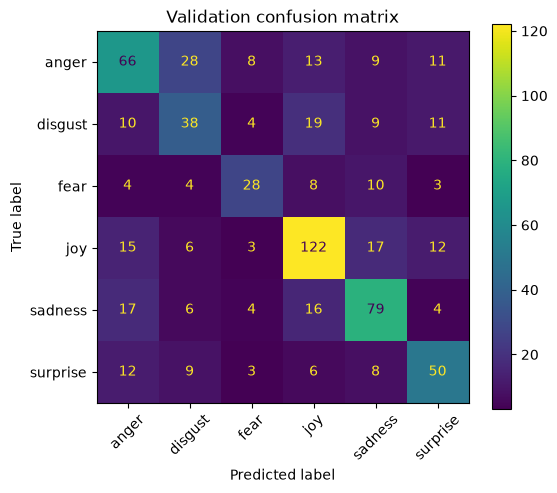

In [15]:
### Add the code related to the model implementation steps in cells inside this section
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# class_weight="balanced" gives rare emotions (fear) more weight
model = LogisticRegression(max_iter=2000, class_weight="balanced", C=1)
model.fit(Xtr, y_tr)
pred = model.predict(Xval)

print("Validation macro F1:", round(f1_score(y_val, pred, average="macro"), 4))
print(classification_report(y_val, pred))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred, labels=model.classes_),
                       display_labels=model.classes_).plot(ax=ax, xticks_rotation=45)
plt.title("Validation confusion matrix"); plt.show()

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline, make_union

# Same features + model, wrapped so each fold re-learns its own vocabulary
pipe = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
               TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)),
    LogisticRegression(max_iter=2000, class_weight="balanced", C=1))

skf = StratifiedKFold(5, shuffle=True, random_state=0)
cv_pred = cross_val_predict(pipe, train_df["clean"], train_df["label"], cv=skf)
print("5-fold macro F1:", round(f1_score(train_df["label"], cv_pred, average="macro"), 4))

5-fold macro F1: 0.5091


In [23]:
# Retrain on ALL 3,360 labeled posts, then predict the 1,440 test posts
pipe.fit(train_df["clean"], train_df["label"])
sub = pd.DataFrame({"post_id": test_df["post_id"],
                    "label":   pipe.predict(test_df["clean"])})

# Safety check: same posts and columns as Kaggle's sample file
sample = pd.read_csv(D + "sampleSubmission.csv")
assert list(sub.columns) == list(sample.columns), "column names differ"
assert set(sub["post_id"]) == set(sample["post_id"]), "post_ids differ"

# Rename columns to match Kaggle's expected format
sub_kaggle = sub.rename(columns={"post_id": "id", "label": "emotion"})
sub_kaggle.to_csv("submission.csv", index=False)
print(sub_kaggle.columns.tolist(), sub_kaggle.shape)   # ['id', 'emotion'] (1440, 2)
display(sub_kaggle.head(10))

['id', 'emotion'] (1440, 2)


,id,emotion
0,xyzx9jp,anger
1,l3vzzxt,fear
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise
5,40acuhg,disgust
6,a7kx7mr,surprise
7,mufm8zo,surprise
8,hvpkfa2,anger
9,rwbrblb,sadness


In [25]:
import datasets, transformers, torch
print(datasets.__version__, transformers.__version__, torch.__version__)
print("Apple GPU (MPS):", torch.backends.mps.is_available())
import pandas as pd, json, numpy as np
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

# --- load data (same as before) ---
D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)

labels = sorted(train_df["label"].unique())          # 6 emotions
l2i = {l: i for i, l in enumerate(labels)}
train_df["y"] = train_df["label"].map(l2i)

tr, va = train_test_split(train_df, test_size=0.2, stratify=train_df["y"], random_state=42)

# --- tokenize ---
MODEL = "j-hartmann/emotion-english-distilroberta-base"
tok = AutoTokenizer.from_pretrained(MODEL)
def prep(d, with_label=True):
    ds = Dataset.from_pandas(d[["text"] + (["y"] if with_label else [])].reset_index(drop=True))
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True)
    return ds.rename_column("y", "labels") if with_label else ds
tr_ds, va_ds = prep(tr), prep(va)
te_ds = prep(test_df, with_label=False)

# --- model: swap the 7-class head for a fresh 6-class one ---
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(labels), ignore_mismatched_sizes=True)

def metrics(p):
    return {"f1": f1_score(p.label_ids, p.predictions.argmax(-1), average="macro")}

args = TrainingArguments(
    output_dir="out", learning_rate=2e-5, num_train_epochs=4,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    eval_strategy="epoch", save_strategy="epoch",      # older versions: evaluation_strategy
    load_best_model_at_end=True, metric_for_best_model="f1",
    weight_decay=0.01, fp16=True, seed=42, report_to="none")

trainer = Trainer(model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
trainer.train()
print(trainer.evaluate())                              # check validation macro F1

# --- predict test and write the Kaggle file ---
logits = trainer.predict(te_ds).predictions
sub = pd.DataFrame({"id": test_df["post_id"],
                    "emotion": [labels[i] for i in logits.argmax(-1)]})
sub.to_csv("submission.csv", index=False)

5.2.0 5.17.0 2.14.1
Apple GPU (MPS): True


config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (19 outputs left out)

/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,F1
0.974184,1.047357,4,0.633743


{'eval_loss': 1.0473570823669434, 'eval_f1': 0.6337431796811973}


/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [26]:
from sklearn.model_selection import StratifiedKFold
from scipy.special import softmax
import torch, gc

K = 5
skf = StratifiedKFold(K, shuffle=True, random_state=42)
oof = np.zeros((len(train_df), len(labels)))          # out-of-fold probabilities
test_probs = np.zeros((len(test_df), len(labels)))    # averaged test probabilities

for fold, (a, b) in enumerate(skf.split(train_df, train_df["y"])):
    tr_ds, va_ds = prep(train_df.iloc[a]), prep(train_df.iloc[b])
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL, num_labels=len(labels), ignore_mismatched_sizes=True)
    args = TrainingArguments(
        output_dir=f"out_fold{fold}", learning_rate=2e-5, num_train_epochs=3,
        per_device_train_batch_size=16, per_device_eval_batch_size=32,
        save_strategy="no", eval_strategy="no",       # fixed 3 epochs, no checkpoints
        weight_decay=0.01, seed=fold, report_to="none")
    trainer = Trainer(model=model, args=args, train_dataset=tr_ds,
                      data_collator=DataCollatorWithPadding(tok))
    trainer.train()

    oof[b] = softmax(trainer.predict(va_ds).predictions, axis=-1)
    test_probs += softmax(trainer.predict(te_ds).predictions, axis=-1) / K
    print(f"fold {fold}: macro F1 = {f1_score(train_df['y'].iloc[b], oof[b].argmax(-1), average='macro'):.4f}")

    del model, trainer; gc.collect(); torch.mps.empty_cache()   # free memory between folds

print("Out-of-fold macro F1:", round(f1_score(train_df["y"], oof.argmax(-1), average="macro"), 4))

# Write the Kaggle file (columns match what Kaggle accepted before)
sub = pd.DataFrame({"id": test_df["post_id"],
                    "emotion": [labels[i] for i in test_probs.argmax(-1)]})
sub.to_csv("submission_ensemble.csv", index=False)

Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
500,0.972283


... (25 outputs left out)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
500,0.990863


fold 4: macro F1 = 0.6187
Out-of-fold macro F1: 0.618


In [28]:
# ===== Ensemble of fine-tuned transformers (5-fold, multiple models) =====
import os, gc, json
import numpy as np, pandas as pd, torch
from datasets import Dataset
from scipy.special import softmax
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

# --- load data ---
D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)
labels = sorted(train_df["label"].unique())
train_df["y"] = train_df["label"].map({l: i for i, l in enumerate(labels)})
y = train_df["y"].values

# --- settings: add or remove models here ---
MODELS = {"A": "j-hartmann/emotion-english-distilroberta-base",   
          "B": "roberta-base"}                                     # new second model
K, EPOCHS, LR = 5, 3, 2e-5
os.makedirs("probs", exist_ok=True)

def run_model(tag, name):
    """5-fold training; saves out-of-fold and averaged test probabilities to disk."""
    tok = AutoTokenizer.from_pretrained(name)
    def prep(d, with_label=True):
        cols = ["text"] + (["y"] if with_label else [])
        ds = Dataset.from_pandas(d[cols].reset_index(drop=True))
        ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=128), batched=True)
        return ds.rename_column("y", "labels") if with_label else ds
    te_ds = prep(test_df, with_label=False)
    oof = np.zeros((len(train_df), len(labels)))
    test_probs = np.zeros((len(test_df), len(labels)))
    skf = StratifiedKFold(K, shuffle=True, random_state=42)
    for fold, (a, b) in enumerate(skf.split(train_df, y)):
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=len(labels), ignore_mismatched_sizes=True)
        args = TrainingArguments(
            output_dir=f"out_{tag}_{fold}", learning_rate=LR, num_train_epochs=EPOCHS,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            save_strategy="no", eval_strategy="no", weight_decay=0.01,
            seed=fold, report_to="none")
        trainer = Trainer(model=model, args=args, train_dataset=prep(train_df.iloc[a]),
                          data_collator=DataCollatorWithPadding(tok))
        trainer.train()
        oof[b] = softmax(trainer.predict(prep(train_df.iloc[b])).predictions, axis=-1)
        test_probs += softmax(trainer.predict(te_ds).predictions, axis=-1) / K
        print(f"[{tag}] fold {fold}: F1 = {f1_score(y[b], oof[b].argmax(-1), average='macro'):.4f}")
        del model, trainer; gc.collect()
        if torch.backends.mps.is_available(): torch.mps.empty_cache()
    np.save(f"probs/{tag}_oof.npy", oof); np.save(f"probs/{tag}_test.npy", test_probs)

# --- train each model (skips any already saved in probs/) ---
for tag, name in MODELS.items():
    if os.path.exists(f"probs/{tag}_oof.npy"):
        print(f"[{tag}] cached, skipping"); continue
    try:
        run_model(tag, name)
    except Exception as e:
        print(f"[{tag}] FAILED ({name}): {e}")

# --- score each model and the blend ---
loaded = {t: (np.load(f"probs/{t}_oof.npy"), np.load(f"probs/{t}_test.npy"))
          for t in MODELS if os.path.exists(f"probs/{t}_oof.npy")}
for t, (o, _) in loaded.items():
    print(f"model {t} OOF macro F1: {f1_score(y, o.argmax(-1), average='macro'):.4f}")
blend_oof  = np.mean([o for o, _ in loaded.values()], axis=0)
blend_test = np.mean([p for _, p in loaded.values()], axis=0)
print("Blend OOF macro F1:", round(f1_score(y, blend_oof.argmax(-1), average="macro"), 4))

# --- optional: tune a weight per emotion on the out-of-fold predictions ---
w = np.ones(len(labels)); best = f1_score(y, blend_oof.argmax(-1), average="macro")
for _ in range(3):
    for c in range(len(labels)):
        for s in [0.6, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0]:
            w2 = w.copy(); w2[c] = s
            f = f1_score(y, (blend_oof * w2).argmax(-1), average="macro")
            if f > best + 1e-4: best, w = f, w2
print("Class weights:", dict(zip(labels, w.round(2))), "| OOF F1 after weights:", round(best, 4))

# --- write the submission ---
USE_WEIGHTS = True
final = blend_test * (w if USE_WEIGHTS else 1.0)
sub = pd.DataFrame({"id": test_df["post_id"],
                    "emotion": [labels[i] for i in final.argmax(-1)]})
sub.to_csv("submission_blend_weighted.csv", index=False)

[A] cached, skipping
[B] cached, skipping
model A OOF macro F1: 0.6223
model B OOF macro F1: 0.6011
Blend OOF macro F1: 0.6309
Class weights: {'anger': np.float64(1.1), 'disgust': np.float64(1.0), 'fear': np.float64(1.0), 'joy': np.float64(0.9), 'sadness': np.float64(1.25), 'surprise': np.float64(0.9)} | OOF F1 after weights: 0.6358


In [32]:
import os, json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# --- 1. Load data to align IDs and true labels ---
D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))

train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)

labels = sorted(train_df["label"].unique())
train_df["y"] = train_df["label"].map({l: i for i, l in enumerate(labels)})
y = train_df["y"].values

# --- 2. Load cached OOF and test probabilities ---
o_A = np.load("probs/A_oof.npy")
p_A = np.load("probs/A_test.npy")

o_B = np.load("probs/B_oof.npy")
p_B = np.load("probs/B_test.npy")

print(f"Model A OOF Macro F1: {f1_score(y, o_A.argmax(-1), average='macro'):.4f}")
print(f"Model B OOF Macro F1: {f1_score(y, o_B.argmax(-1), average='macro'):.4f}")

# --- 3. Grid search optimal blend ratio (alpha for Model A, 1-alpha for Model B) ---
best_alpha = 0.5
best_f1 = 0.0

for alpha in np.linspace(0.05, 0.95, 37):
    blend_oof = alpha * o_A + (1.0 - alpha) * o_B
    score = f1_score(y, blend_oof.argmax(-1), average="macro")
    if score > best_f1:
        best_f1 = score
        best_alpha = alpha

print("=" * 50)
print(f"Equal 50/50 Blend OOF F1: {f1_score(y, (0.5 * o_A + 0.5 * o_B).argmax(-1), average='macro'):.4f}")
print(f"Optimal Alpha for Model A: {best_alpha:.2f} (Model B weight: {1.0 - best_alpha:.2f})")
print(f"Optimized Blend OOF F1:   {best_f1:.4f}")
print("=" * 50)

# --- 4. Generate final test predictions using optimal blend ---
final_test_probs = best_alpha * p_A + (1.0 - best_alpha) * p_B

sub = pd.DataFrame({
    "id": test_df["post_id"],
    "emotion": [labels[i] for i in final_test_probs.argmax(-1)]
})

output_filename = "submission_optimal_blend.csv"
sub.to_csv(output_filename, index=False)
print(f"Saved: {output_filename}")
print(f"Shape: {sub.shape}")
print("\nClass distribution:")
print(sub["emotion"].value_counts())

Model A OOF Macro F1: 0.6223
Model B OOF Macro F1: 0.6011
Equal 50/50 Blend OOF F1: 0.6309
Optimal Alpha for Model A: 0.55 (Model B weight: 0.45)
Optimized Blend OOF F1:   0.6322
Saved: submission_optimal_blend.csv
Shape: (1440, 2)

Class distribution:
emotion
joy         392
anger       339
sadness     271
surprise    200
disgust     133
fear        105
Name: count, dtype: int64


In [1]:
import os, gc, re, json, shutil, subprocess
import numpy as np, pandas as pd, torch
from datasets import Dataset
from scipy.special import softmax
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

awake = subprocess.Popen(["caffeinate", "-i"])          # keep the Mac awake
try:
    D = "2026-dm-lab-2-private-competition/"
    posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
    df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
               .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))
    def clean_text(t):
        t = re.sub(r"http\S+|www\S+", "http", str(t))
        t = re.sub(r"@\w+", "@user", t)
        return re.sub(r"\s+", " ", t.replace("&amp;", "&")).strip()
    df["text"] = df["text"].map(clean_text)
    train_df = df[df["set"] == "train"].reset_index(drop=True)
    test_df  = df[df["set"] == "test"].reset_index(drop=True)
    labels = sorted(train_df["label"].unique())
    train_df["y"] = train_df["label"].map({l: i for i, l in enumerate(labels)})
    y = train_df["y"].values
    os.makedirs("probs", exist_ok=True)

    RUNS = [  # (tag, model, seed, learning_rate, epochs)
        ("A_s7",  "j-hartmann/emotion-english-distilroberta-base",        7, 2e-5, 3),
        ("F",     "bhadresh-savani/distilbert-base-uncased-emotion",      42, 3e-5, 3),
        ("B_s7",  "roberta-base",                                          7, 2e-5, 3),
        ("A_s99", "j-hartmann/emotion-english-distilroberta-base",        99, 2e-5, 3),
    ]
    K, MAX_LEN, MIN_OOF = 5, 128, 0.55

    def run(tag, name, seed, lr, epochs):
        print(f"\n{'='*60}\n[{tag}] {name} | seed {seed}\n{'='*60}")
        tok = AutoTokenizer.from_pretrained(name)
        def prep(d, with_label=True):
            ds = Dataset.from_pandas(d[["text"] + (["y"] if with_label else [])].reset_index(drop=True))
            ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
            return ds.rename_column("y", "labels") if with_label else ds
        te_ds = prep(test_df, with_label=False)
        oof = np.zeros((len(train_df), len(labels)))
        test_probs = np.zeros((len(test_df), len(labels)))
        for fold, (a, b) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(train_df, y)):
            model = AutoModelForSequenceClassification.from_pretrained(
                name, num_labels=len(labels), ignore_mismatched_sizes=True,
                problem_type="single_label_classification")
            args = TrainingArguments(
                output_dir=f"out_{tag}_{fold}", learning_rate=lr, num_train_epochs=epochs,
                per_device_train_batch_size=16, per_device_eval_batch_size=32,
                save_strategy="no", eval_strategy="no", weight_decay=0.01,
                seed=seed + fold, report_to="none")
            tr = Trainer(model=model, args=args, train_dataset=prep(train_df.iloc[a]),
                         data_collator=DataCollatorWithPadding(tok))
            tr.train()
            oof[b] = softmax(tr.predict(prep(train_df.iloc[b])).predictions, axis=-1)
            test_probs += softmax(tr.predict(te_ds).predictions, axis=-1) / K
            print(f"[{tag}] fold {fold}: F1 = {f1_score(y[b], oof[b].argmax(-1), average='macro'):.4f}")
            del model, tr; gc.collect()
            if torch.backends.mps.is_available(): torch.mps.empty_cache()
            shutil.rmtree(f"out_{tag}_{fold}", ignore_errors=True)
        f1 = f1_score(y, oof.argmax(-1), average="macro")
        if f1 < MIN_OOF:                                   # never save a broken model
            print(f"[{tag}] OOF F1 {f1:.4f} < {MIN_OOF}: NOT saved"); return
        np.save(f"probs/{tag}_oof.npy", oof); np.save(f"probs/{tag}_test.npy", test_probs)
        print(f"--> [{tag}] saved | OOF macro F1 = {f1:.4f}")

    for tag, name, seed, lr, ep in RUNS:
        if os.path.exists(f"probs/{tag}_oof.npy"):
            print(f"[{tag}] cached, skipping"); continue
        try:
            run(tag, name, seed, lr, ep)
        except Exception as e:
            print(f"[{tag}] FAILED ({name}): {e}")
            gc.collect()
finally:
    awake.terminate()
print("\nSaved so far:", sorted(f for f in os.listdir("probs") if f.endswith("_oof.npy")))


[A_s7] j-hartmann/emotion-english-distilroberta-base | seed 7


Map:   0%|          | 0/1440 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Map:   0%|          | 0/2688 [00:00<?, ? examples/s]

... (166 outputs left out)

Step,Training Loss
500,0.979830


Map:   0%|          | 0/672 [00:00<?, ? examples/s]

/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


[A_s99] fold 4: F1 = 0.6479
--> [A_s99] saved | OOF macro F1 = 0.6230

Saved so far: ['A_oof.npy', 'A_s7_oof.npy', 'A_s99_oof.npy', 'B_oof.npy', 'B_s7_oof.npy', 'F_oof.npy', 'tfidf_oof.npy']


In [6]:
import os, gc, re, json, shutil, subprocess
import numpy as np, pandas as pd, torch
import torch.nn as nn
from datasets import Dataset
from scipy.special import softmax
from scipy.optimize import minimize
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

awake = subprocess.Popen(["caffeinate", "-i"])  # keep Mac awake during training
try:
    # 1. Load data & preserve casing/emojis (crucial for emotion cues)
    D = "2026-dm-lab-2-private-competition/"
    posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
    df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
               .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))

    def clean_for_transformer(t):
        t = re.sub(r"http\S+|www\.\S+", "http", str(t))
        t = re.sub(r"@\w+", "@user", t)
        return re.sub(r"\s+", " ", t.replace("&amp;", "&")).strip()

    df["text"] = df["text"].map(clean_for_transformer)
    train_df = df[df["set"] == "train"].reset_index(drop=True)
    test_df  = df[df["set"] == "test"].reset_index(drop=True)
    labels = sorted(train_df["label"].unique())
    train_df["y"] = train_df["label"].map({l: i for i, l in enumerate(labels)})
    y = train_df["y"].values
    os.makedirs("probs", exist_ok=True)

    # 2. Smoothed class weights for Macro F1
    raw_weights = compute_class_weight("balanced", classes=np.unique(y), y=y)
    class_weights = torch.tensor(np.sqrt(raw_weights), dtype=torch.float)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            lbls = inputs.pop("labels")
            outputs = model(**inputs)
            loss_fct = nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device))
            loss = loss_fct(outputs.logits.view(-1, self.model.config.num_labels), lbls.view(-1))
            return (loss, outputs) if return_outputs else loss

    # 3. High-performing BPE backbones (no SentencePiece needed)
    NEW_RUNS = [
        ("goemo",   "SamLowe/roberta-base-go_emotions",                        42, 2e-5, 4),
        ("twitter", "cardiffnlp/twitter-roberta-base-emotion-multilabel-latest", 42, 2e-5, 4),
    ]
    K, MAX_LEN = 5, 128

    for tag, name, seed, lr, epochs in NEW_RUNS:
        if os.path.exists(f"probs/{tag}_oof.npy"):
            print(f"[{tag}] cached, skipping")
            continue
        print(f"\n{'='*60}\n[{tag}] {name}\n{'='*60}")
        tok = AutoTokenizer.from_pretrained(name)

        def prep(d, with_label=True):
            cols = ["text"] + (["y"] if with_label else [])
            ds = Dataset.from_pandas(d[cols].reset_index(drop=True))
            ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
            return ds.rename_column("y", "labels") if with_label else ds

        te_ds = prep(test_df, with_label=False)
        oof = np.zeros((len(train_df), len(labels)))
        test_probs = np.zeros((len(test_df), len(labels)))

        for fold, (a, b) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(train_df, y)):
            model = AutoModelForSequenceClassification.from_pretrained(
                name, num_labels=len(labels), ignore_mismatched_sizes=True)
            args = TrainingArguments(
                output_dir=f"out_{tag}_{fold}",
                learning_rate=lr,
                num_train_epochs=epochs,
                per_device_train_batch_size=16,
                per_device_eval_batch_size=32,
                warmup_steps=0.1,
                lr_scheduler_type="cosine",
                weight_decay=0.01,
                save_strategy="no",
                eval_strategy="no",
                seed=seed + fold,
                report_to="none",
            )
            tr = WeightedTrainer(model=model, args=args, train_dataset=prep(train_df.iloc[a]),
                                 data_collator=DataCollatorWithPadding(tok))
            tr.train()
            oof[b] = softmax(tr.predict(prep(train_df.iloc[b])).predictions, axis=-1)
            test_probs += softmax(tr.predict(te_ds).predictions, axis=-1) / K
            print(f"[{tag}] fold {fold}: F1 = {f1_score(y[b], oof[b].argmax(-1), average='macro'):.4f}")
            del model, tr; gc.collect()
            if torch.backends.mps.is_available(): torch.mps.empty_cache()
            shutil.rmtree(f"out_{tag}_{fold}", ignore_errors=True)

        f1 = f1_score(y, oof.argmax(-1), average="macro")
        np.save(f"probs/{tag}_oof.npy", oof)
        np.save(f"probs/{tag}_test.npy", test_probs)
        print(f"--> [{tag}] saved | OOF macro F1 = {f1:.4f}")

finally:
    awake.terminate()

# 4. Weighted Ensemble combining new + existing strong cached models
model_weights = {
    "twitter": 0.35,
    "goemo":   0.30,
    "A_s99":   0.12,
    "A":       0.10,
    "B":       0.08,
    "tfidf":   0.05,
}

blend_oof  = np.zeros((len(train_df), len(labels)))
blend_test = np.zeros((len(test_df), len(labels)))
total_w = 0.0

for tag, w in model_weights.items():
    oof_p, test_p = f"probs/{tag}_oof.npy", f"probs/{tag}_test.npy"
    if os.path.exists(oof_p) and os.path.exists(test_p):
        o, p = np.load(oof_p), np.load(test_p)
        print(f"Loaded {tag:8s} | OOF F1: {f1_score(y, o.argmax(-1), average='macro'):.4f} | weight: {w}")
        blend_oof  += w * o
        blend_test += w * p
        total_w += w

blend_oof  /= total_w
blend_test /= total_w
print(f"\nWeighted Blend OOF Macro F1: {f1_score(y, blend_oof.argmax(-1), average='macro'):.4f}")

# 5. Nested-CV Class Multiplier Tuning (prevents OOF overfitting)
def optimize_multipliers(probs, y_true):
    def loss(w):
        return -f1_score(y_true, (probs * w).argmax(axis=1), average="macro")
    return minimize(loss, np.ones(len(labels)), method="Nelder-Mead", options={"maxiter": 600}).x

skf = StratifiedKFold(5, shuffle=True, random_state=42)
nested_preds = np.zeros_like(blend_oof)
fold_mults = []

for tr_idx, va_idx in skf.split(blend_oof, y):
    m = optimize_multipliers(blend_oof[tr_idx], y[tr_idx])
    fold_mults.append(m)
    nested_preds[va_idx] = blend_oof[va_idx] * m

print(f"Nested CV Tuned OOF Macro F1: {f1_score(y, nested_preds.argmax(-1), average='macro'):.4f}")

avg_mults = np.mean(fold_mults, axis=0)
final_test_probs = blend_test * avg_mults

sub = pd.DataFrame({
    "id": test_df["post_id"],
    "emotion": [labels[i] for i in final_test_probs.argmax(-1)]
})
sub.to_csv("submission_boosted.csv", index=False)
print("Saved submission_boosted.csv", sub.shape)
print(sub["emotion"].value_counts())

python(56319) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


[goemo] cached, skipping

[twitter] cardiffnlp/twitter-roberta-base-emotion-multilabel-latest


Map:   0%|          | 0/1440 [00:00<?, ? examples/s]

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `11`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-emotion-multilabel-latest
Key                        | Status   |                                                                                        
---------------------------+----------+----------------------------------------------------------------------------------------
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([11]) vs model:torch.Size([6])          
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([11, 768]) vs model:torch.Size([6, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


... (38 outputs left out)

Step,Training Loss
500,1.006727


Map:   0%|          | 0/672 [00:00<?, ? examples/s]

/Users/diana/Documents/Masters/DM2026-Lab2-Exercise/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


[twitter] fold 4: F1 = 0.5991
--> [twitter] saved | OOF macro F1 = 0.6035
Loaded twitter  | OOF F1: 0.6035 | weight: 0.35
Loaded goemo    | OOF F1: 0.6177 | weight: 0.3
Loaded A_s99    | OOF F1: 0.6230 | weight: 0.12
Loaded A        | OOF F1: 0.6223 | weight: 0.1
Loaded B        | OOF F1: 0.6011 | weight: 0.08
Loaded tfidf    | OOF F1: 0.5053 | weight: 0.05

Weighted Blend OOF Macro F1: 0.6356
Nested CV Tuned OOF Macro F1: 0.6354
Saved submission_boosted.csv (1440, 2)
emotion
joy         380
anger       326
sadness     260
surprise    209
disgust     143
fear        122
Name: count, dtype: int64


In [1]:
# ===== GPU-Trained Large Transformer Backbones (Run on Google Colab T4 GPU) =====
# Trains 5-fold CV for large emotion-pretrained checkpoints using WeightedTrainer
# Skips automatically if OOF/test probabilities are already cached in probs/

import os, gc, re, json, shutil
import numpy as np, pandas as pd, torch
import torch.nn as nn
from datasets import Dataset
from scipy.special import softmax
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

# 1. Load data & preserve casing/emoticons for transformer tokenization
D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))

def clean_for_transformer(t):
    t = re.sub(r"http\S+|www\.\S+", "http", str(t))
    t = re.sub(r"@\w+", "@user", t)
    return re.sub(r"\s+", " ", t.replace("&amp;", "&")).strip()

df["text"] = df["text"].map(clean_for_transformer)
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)
labels = sorted(train_df["label"].unique())
train_df["y"] = train_df["label"].map({l: i for i, l in enumerate(labels)})
y = train_df["y"].values
os.makedirs("probs", exist_ok=True)

# 2. Smoothed inverse-frequency class weights for Macro F1 optimization
raw_weights = compute_class_weight("balanced", classes=np.unique(y), y=y)
class_weights = torch.tensor(np.sqrt(raw_weights), dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, label_smoothing=0.0, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.label_smoothing = label_smoothing

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        lbls = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        loss_fct = nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device),
            label_smoothing=self.label_smoothing
        )
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), lbls.view(-1))
        return (loss, outputs) if return_outputs else loss

# 3. Large models trained on Colab T4 GPU
# (tag, model_name, seed, lr, epochs, batch_size, grad_accum, label_smoothing)
LARGE_RUNS = [
    ("hartmann_large",    "j-hartmann/emotion-english-roberta-large",           42, 1e-5, 4, 16, 1, 0.0),
    ("twitter_large",     "cardiffnlp/twitter-roberta-large-emotion-latest",    42, 1e-5, 4, 16, 1, 0.05),
    ("deberta_emo_large", "duelker/samo-goemotions-deberta-v3-large",           42, 8e-6, 4,  8, 2, 0.0),
]
K, MAX_LEN = 5, 128

for tag, name, seed, lr, epochs, bs, accum, smooth in LARGE_RUNS:
    if os.path.exists(f"probs/{tag}_oof.npy"):
        oof_cached = np.load(f"probs/{tag}_oof.npy")
        print(f"[{tag}] cached | OOF macro F1 = {f1_score(y, oof_cached.argmax(-1), average='macro'):.4f}")
        continue

    print(f"\n{'='*60}\n[{tag}] {name}\n{'='*60}")
    tok = AutoTokenizer.from_pretrained(name)

    def prep(d, with_label=True):
        cols = ["text"] + (["y"] if with_label else [])
        ds = Dataset.from_pandas(d[cols].reset_index(drop=True))
        ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
        return ds.rename_column("y", "labels") if with_label else ds

    te_ds = prep(test_df, with_label=False)
    oof = np.zeros((len(train_df), len(labels)))
    test_probs = np.zeros((len(test_df), len(labels)))

    use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
    use_fp16 = torch.cuda.is_available() and not use_bf16

    for fold, (a, b) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(train_df, y)):
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=len(labels), ignore_mismatched_sizes=True)
        args = TrainingArguments(
            output_dir=f"out_{tag}_{fold}",
            learning_rate=lr,
            num_train_epochs=epochs,
            per_device_train_batch_size=bs,
            gradient_accumulation_steps=accum,
            per_device_eval_batch_size=32,
            warmup_steps=0.1,
            lr_scheduler_type="cosine",
            weight_decay=0.01,
            bf16=use_bf16,
            fp16=use_fp16,
            save_strategy="no",
            eval_strategy="no",
            seed=seed + fold,
            report_to="none",
        )
        tr = WeightedTrainer(label_smoothing=smooth, model=model, args=args,
                             train_dataset=prep(train_df.iloc[a]),
                             data_collator=DataCollatorWithPadding(tok))
        tr.train()
        oof[b] = softmax(tr.predict(prep(train_df.iloc[b])).predictions, axis=-1)
        test_probs += softmax(tr.predict(te_ds).predictions, axis=-1) / K
        print(f"[{tag}] fold {fold}: F1 = {f1_score(y[b], oof[b].argmax(-1), average='macro'):.4f}")
        del model, tr; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        shutil.rmtree(f"out_{tag}_{fold}", ignore_errors=True)

    f1 = f1_score(y, oof.argmax(-1), average="macro")
    np.save(f"probs/{tag}_oof.npy", oof)
    np.save(f"probs/{tag}_test.npy", test_probs)
    print(f"--> [{tag}] saved | OOF macro F1 = {f1:.4f}")

[hartmann_large] cached | OOF macro F1 = 0.6189
[twitter_large] cached | OOF macro F1 = 0.6216
[deberta_emo_large] cached | OOF macro F1 = 0.6207


In [3]:
# ===== Semi-Supervised Pseudo-Labeling (Run on Google Colab T4 GPU) =====
# Augments each training fold with high-confidence ensemble pseudo-labels from test_df
# Validation folds remain strictly untouched to prevent data leakage

tag, name, seed, lr, epochs = "hartmann_pseudo", "j-hartmann/emotion-english-roberta-large", 77, 1e-5, 4

if os.path.exists(f"probs/{tag}_oof.npy"):
    oof_cached = np.load(f"probs/{tag}_oof.npy")
    print(f"[{tag}] cached | OOF macro F1 = {f1_score(y, oof_cached.argmax(-1), average='macro'):.4f}")
else:
    # Load pseudo-labels generated by earlier ensemble (submission_final_v5.csv)
    pseudo = pd.read_csv("submission_final_v5.csv").rename(columns={"id": "post_id", "emotion": "label"})
    test_pseudo = test_df[["post_id", "text"]].merge(pseudo, on="post_id")
    test_pseudo["y"] = test_pseudo["label"].map({l: i for i, l in enumerate(labels)})

    print(f"\n{'='*60}\n[{tag}] {name} (with Pseudo-Labels)\n{'='*60}")
    tok = AutoTokenizer.from_pretrained(name)

    def prep(d, with_label=True):
        cols = ["text"] + (["y"] if with_label else [])
        ds = Dataset.from_pandas(d[cols].reset_index(drop=True))
        ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
        return ds.rename_column("y", "labels") if with_label else ds

    te_ds = prep(test_df, with_label=False)
    oof = np.zeros((len(train_df), len(labels)))
    test_probs = np.zeros((len(test_df), len(labels)))

    for fold, (a, b) in enumerate(StratifiedKFold(K, shuffle=True, random_state=42).split(train_df, y)):
        # Combine fold training split + pseudo-labeled test posts
        fold_train = pd.concat([train_df.iloc[a][["text", "y"]], test_pseudo[["text", "y"]]], ignore_index=True)
        model = AutoModelForSequenceClassification.from_pretrained(
            name, num_labels=len(labels), ignore_mismatched_sizes=True)
        args = TrainingArguments(
            output_dir=f"out_{tag}_{fold}",
            learning_rate=lr,
            num_train_epochs=epochs,
            per_device_train_batch_size=16,
            per_device_eval_batch_size=32,
            warmup_steps=0.1,
            lr_scheduler_type="cosine",
            weight_decay=0.01,
            fp16=torch.cuda.is_available(),
            save_strategy="no",
            eval_strategy="no",
            seed=seed + fold,
            report_to="none",
        )
        tr = WeightedTrainer(model=model, args=args, train_dataset=prep(fold_train),
                             data_collator=DataCollatorWithPadding(tok))
        tr.train()
        oof[b] = softmax(tr.predict(prep(train_df.iloc[b])).predictions, axis=-1)
        test_probs += softmax(tr.predict(te_ds).predictions, axis=-1) / K
        print(f"[{tag}] fold {fold}: F1 = {f1_score(y[b], oof[b].argmax(-1), average='macro'):.4f}")
        del model, tr; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        shutil.rmtree(f"out_{tag}_{fold}", ignore_errors=True)

    f1 = f1_score(y, oof.argmax(-1), average="macro")
    np.save(f"probs/{tag}_oof.npy", oof)
    np.save(f"probs/{tag}_test.npy", test_probs)
    print(f"--> [{tag}] saved | OOF macro F1 = {f1:.4f}")

[hartmann_pseudo] cached | OOF macro F1 = 0.6371


In [17]:
import json
import numpy as np, pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)
labels = sorted(train_df["label"].unique())
y = train_df["label"].map({l: i for i, l in enumerate(labels)}).values

tags = [
    "hartmann_large",
    "twitter_large",
    "goemo",
    "A_s99",
    "A",
    "A_s7",
    "twitter",
    "hartmann_pseudo",
]

eps = 1e-6
log_oofs  = np.stack([np.log(np.clip(np.load(f"probs/{t}_oof.npy"),  eps, 1 - eps)) for t in tags], axis=0)
log_tests = np.stack([np.log(np.clip(np.load(f"probs/{t}_test.npy"), eps, 1 - eps)) for t in tags], axis=0)

# Anchor = your 0.6461 champion + twitter_large
anchor = np.array([0.29, 0.14, 0.23, 0.11, 0.10, 0.06, 0.03, 0.04])
anchor /= anchor.sum()

rng = np.random.default_rng(42)
candidates = [anchor]
for _ in range(3000):
    w = np.maximum(anchor + rng.normal(0, 0.04, size=len(tags)), 0)
    if w.sum() > 0:
        candidates.append(w / w.sum())
candidates = np.array(candidates)  # (3001, 8)

# Nested 5-Fold CV selection (prevents any overfitting on train OOF)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
nested_oof = np.zeros_like(log_oofs[0])
fold_best_w = []

for tr_idx, va_idx in skf.split(train_df, y):
    best_f1, best_w = -1.0, anchor
    for w in candidates:
        blend = np.tensordot(w, log_oofs[:, tr_idx, :], axes=(0, 0))
        score = f1_score(y[tr_idx], blend.argmax(-1), average="macro")
        if score > best_f1:
            best_f1, best_w = score, w
    fold_best_w.append(best_w)
    nested_oof[va_idx] = np.tensordot(best_w, log_oofs[:, va_idx, :], axes=(0, 0))

final_w = np.mean(fold_best_w, axis=0)
final_w /= final_w.sum()

nested_f1 = f1_score(y, nested_oof.argmax(-1), average="macro")
full_oof  = np.tensordot(final_w, log_oofs, axes=(0, 0))
full_f1   = f1_score(y, full_oof.argmax(-1), average="macro")

print(f"Nested 5-Fold CV Macro F1: {nested_f1:.4f}")
print(f"Full OOF Macro F1:         {full_f1:.4f}\n")
for t, w in zip(tags, final_w):
    print(f"  {t:16s}: {w:.4f}")

final_test = np.tensordot(final_w, log_tests, axes=(0, 0))
sub = pd.DataFrame({
    "id": test_df["post_id"],
    "emotion": [labels[i] for i in final_test.argmax(-1)]
})
sub.to_csv("submission_final_v10.csv", index=False)
print("\nSaved submission_final_v10.csv", sub.shape)
print(sub["emotion"].value_counts())

Nested 5-Fold CV Macro F1: 0.6470
Full OOF Macro F1:         0.6522

  hartmann_large  : 0.2412
  twitter_large   : 0.1536
  goemo           : 0.2371
  A_s99           : 0.1171
  A               : 0.1136
  A_s7            : 0.0301
  twitter         : 0.0716
  hartmann_pseudo : 0.0356

Saved submission_final_v10.csv (1440, 2)
emotion
joy         383
anger       333
sadness     264
surprise    197
disgust     147
fear        116
Name: count, dtype: int64


In [20]:
import json
import numpy as np, pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

D = "2026-dm-lab-2-private-competition/"
posts = pd.DataFrame(json.load(open(D + "final_posts.json", encoding="utf-8")))
df = (posts.merge(pd.read_csv(D + "data_identification.csv"), on="post_id")
           .merge(pd.read_csv(D + "emotion.csv"), on="post_id", how="left"))
train_df = df[df["set"] == "train"].reset_index(drop=True)
test_df  = df[df["set"] == "test"].reset_index(drop=True)
labels = sorted(train_df["label"].unique())
y = train_df["label"].map({l: i for i, l in enumerate(labels)}).values

tags = [
    "hartmann_large",
    "deberta_emo_large",
    "twitter_large",
    "goemo",
    "A_s99",
    "A",
    "A_s7",
    "twitter",
    "hartmann_pseudo",
]

eps = 1e-6
log_oofs  = np.stack([np.log(np.clip(np.load(f"probs/{t}_oof.npy"),  eps, 1 - eps)) for t in tags], axis=0)
log_tests = np.stack([np.log(np.clip(np.load(f"probs/{t}_test.npy"), eps, 1 - eps)) for t in tags], axis=0)

# Anchor = your 0.6470 champion + deberta_emo_large (16%)
anchor = np.array([0.21, 0.16, 0.14, 0.20, 0.10, 0.09, 0.025, 0.045, 0.03])
anchor /= anchor.sum()

rng = np.random.default_rng(42)
candidates = [anchor]
for _ in range(4000):
    w = np.maximum(anchor + rng.normal(0, 0.035, size=len(tags)), 0)
    if w.sum() > 0:
        candidates.append(w / w.sum())
candidates = np.array(candidates)  # (4001, 9)

# Nested 5-Fold CV selection (prevents any overfitting on train OOF)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
nested_oof = np.zeros_like(log_oofs[0])
fold_best_w = []

for tr_idx, va_idx in skf.split(train_df, y):
    best_f1, best_w = -1.0, anchor
    for w in candidates:
        blend = np.tensordot(w, log_oofs[:, tr_idx, :], axes=(0, 0))
        score = f1_score(y[tr_idx], blend.argmax(-1), average="macro")
        if score > best_f1:
            best_f1, best_w = score, w
    fold_best_w.append(best_w)
    nested_oof[va_idx] = np.tensordot(best_w, log_oofs[:, va_idx, :], axes=(0, 0))

final_w = np.mean(fold_best_w, axis=0)
final_w /= final_w.sum()

nested_f1 = f1_score(y, nested_oof.argmax(-1), average="macro")
full_oof  = np.tensordot(final_w, log_oofs, axes=(0, 0))
full_f1   = f1_score(y, full_oof.argmax(-1), average="macro")

print(f"Nested 5-Fold CV Macro F1: {nested_f1:.4f}")
print(f"Full OOF Macro F1:         {full_f1:.4f}\n")
for t, w in zip(tags, final_w):
    print(f"  {t:18s}: {w:.4f}")

final_test = np.tensordot(final_w, log_tests, axes=(0, 0))
sub = pd.DataFrame({
    "id": test_df["post_id"],
    "emotion": [labels[i] for i in final_test.argmax(-1)]
})
sub.to_csv("submission_final_v11.csv", index=False)
print("\nSaved submission_final_v11.csv", sub.shape)
print(sub["emotion"].value_counts())

Nested 5-Fold CV Macro F1: 0.6476
Full OOF Macro F1:         0.6518

  hartmann_large    : 0.1857
  deberta_emo_large : 0.1594
  twitter_large     : 0.1157
  goemo             : 0.2075
  A_s99             : 0.1334
  A                 : 0.1084
  A_s7              : 0.0156
  twitter           : 0.0516
  hartmann_pseudo   : 0.0228

Saved submission_final_v11.csv (1440, 2)
emotion
joy         386
anger       330
sadness     269
surprise    197
disgust     140
fear        118
Name: count, dtype: int64
